# 05 - Classificação com Encoder-Decoder

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Conv2DTranspose, GlobalAveragePooling2D, Dropout, Activation

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
tf.keras.utils.set_random_seed(0)
print(tf.config.list_physical_devices('GPU'))

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Carregamento dos dados

In [2]:
splits = pd.read_csv(PROJECT_ROOT / 'data' / 'annotations' / 'splits.csv')
classes = sorted(splits['classe'].unique())
print(classes)

def carregar(conjunto):
    df = splits[splits['conjunto'] == conjunto]
    X, y = [], []
    for _, row in df.iterrows():
        caminho = PROJECT_ROOT / row['caminho'].replace('spectrograms', 'mod_spectograms')
        img = Image.open(caminho).convert('RGB').resize((224, 224))
        X.append(np.array(img) / 255.0)
        y.append(classes.index(row['classe']))
    return np.array(X, dtype='float32'), np.array(y)

X_train, y_train = carregar('treino')
X_val, y_val = carregar('validacao')
print(X_train.shape, X_val.shape)

def plotar_historico(history, titulo):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, metrica, nome in zip(axes, ['loss', 'accuracy'], ['Perda', 'Acurácia']):
        ax.plot(history.history[metrica], label='Treinamento')
        ax.plot(history.history['val_' + metrica], label='Validação')
        ax.set_title(f'{titulo} — {nome}')
        ax.set_xlabel('Épocas')
        ax.set_ylabel(metrica)
        ax.legend()
    plt.tight_layout()
    plt.show()

['ICTAL', 'NORMAL', 'POS_ICTAL', 'PRE_ICTAL']


(100, 224, 224, 3) (20, 224, 224, 3)


## Arquitetura

In [3]:
encdec = Sequential([
    Input(shape=(224, 224, 3)),
    # Encoder (mesmo extrator de features da CNN e da FCNN)
    Conv2D(32, (3, 3), activation='relu', padding='same'),    # 224x224x32
    MaxPooling2D((2, 2)),                                     # 112x112x32
    Conv2D(64, (3, 3), activation='relu', padding='same'),    # 112x112x64
    MaxPooling2D((2, 2)),                                     # 56x56x64
    Conv2D(128, (3, 3), activation='relu', padding='same'),   # 56x56x128
    MaxPooling2D((2, 2)),                                     # 28x28x128
    # Decoder (espelho do encoder)
    Conv2DTranspose(128, (3, 3), strides=2, activation='relu', padding='same'),  # 56x56x128
    Conv2DTranspose(64, (3, 3), strides=2, activation='relu', padding='same'),   # 112x112x64
    Conv2DTranspose(32, (3, 3), strides=2, activation='relu', padding='same'),   # 224x224x32
    # Classificador (igual ao da FCNN)
    Conv2D(128, (1, 1), activation='relu'),                   # no lugar da Dense(128)
    Dropout(0.5),
    Conv2D(4, (1, 1)),                                        # no lugar da Dense(4): 1 mapa por classe
    GlobalAveragePooling2D(),                                 # 4 (no lugar do Flatten)
    Activation('softmax'),
])

encdec.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 56, 56, 128)    │       147,584 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 112, 112, 64)   │        73,792 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 224, 224, 32)   │        18,464 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 224, 224, 128)  │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 224, 224, 128)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 224, 224, 4)    │           516 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 4)              │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 4)              │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 337,828 (1.29 MB)

 Trainable params: 337,828 (1.29 MB)

 Non-trainable params: 0 (0.00 B)

## Treinamento

In [4]:
encdec.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
history_encdec = encdec.fit(X_train, y_train, epochs=30, validation_data=(X_val, y_val), verbose=2)

Epoch 1/30


4/4 - 21s - 5s/step - accuracy: 0.1700 - loss: 1.3868 - val_accuracy: 0.2500 - val_loss: 1.3859


Epoch 2/30


4/4 - 0s - 82ms/step - accuracy: 0.2500 - loss: 1.3863 - val_accuracy: 0.2500 - val_loss: 1.3844


Epoch 3/30


4/4 - 0s - 82ms/step - accuracy: 0.2500 - loss: 1.3856 - val_accuracy: 0.2500 - val_loss: 1.3758


... (50 outputs left out)

Epoch 29/30


4/4 - 0s - 93ms/step - accuracy: 0.3500 - loss: 1.2893 - val_accuracy: 0.4500 - val_loss: 1.2165


Epoch 30/30


4/4 - 0s - 87ms/step - accuracy: 0.3500 - loss: 1.2863 - val_accuracy: 0.4000 - val_loss: 1.2240


## Gráficos

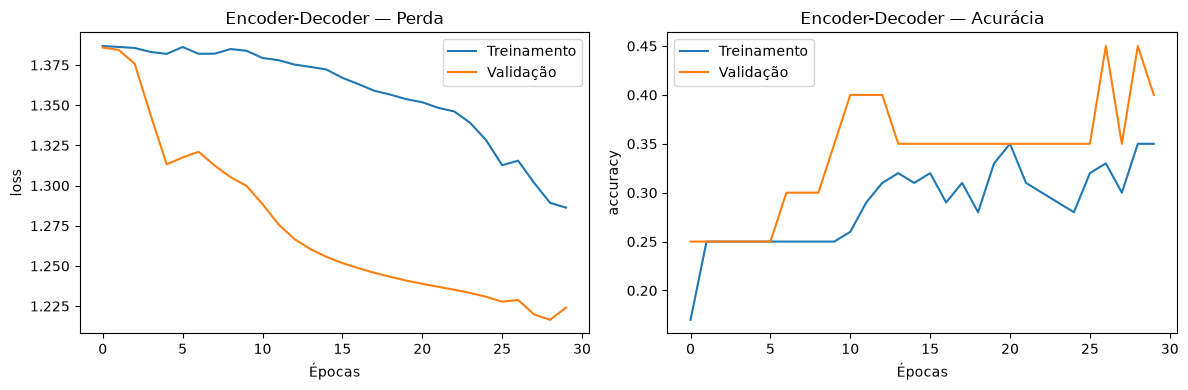

In [5]:
plotar_historico(history_encdec, 'Encoder-Decoder')

## Salvando o modelo

In [6]:
encdec.save(PROJECT_ROOT / 'models' / 'modelo_encdec.keras')